In [1]:
import os, sys
sys.path.append(os.path.abspath(".."))     # so we can import from project root
import pandas as pd
import numpy as np
import sqlite3
import joblib
from datetime import datetime
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# load data from SQLite with JOINS (this is where relationships shine)

conn = sqlite3.connect("../logistics.db")

query = """
SELECT s.id, s.distance_km, s.weight_kg, s.priority, s.promised_date,
       s.actual_delivery_date, s.created_at,
       c.reliability_score AS carrier_reliability,
       v.year AS vehicle_year
FROM shipments s
JOIN carriers c ON s.carrier_id = c.id
LEFT JOIN vehicles v ON s.vehicle_id = v.id
WHERE s.actual_delivery_date IS NOT NULL
"""
df = pd.read_sql_query(query, conn)
conn.close()
print("Rows:", len(df))
df.head()

Rows: 4295


,id,distance_km,weight_kg,priority,promised_date,actual_delivery_date,created_at,carrier_reliability,vehicle_year
0,1,1581.9,417.5,Standard,2023-10-20T17:44:06.368694,2023-10-20T16:02:06.368694,2023-10-19,0.93,2018
1,2,120.2,341.4,Express,2023-10-19T01:36:00.608702,2023-10-19T00:20:00.608702,2023-10-19,0.89,2020
2,3,1560.7,488.1,Express,2023-10-20T05:54:07.302438,2023-10-20T06:02:07.302438,2023-10-19,0.89,2018
3,4,914.4,80.4,Express,2023-10-19T16:09:20.237169,2023-10-19T15:09:20.237169,2023-10-19,0.85,2019
4,5,1607.1,153.3,Express,2023-10-20T04:07:49.375019,2023-10-20T01:56:49.375019,2023-10-19,0.85,2018


In [3]:
# feature engineering: compute actual hours

df["promised_dt"] = pd.to_datetime(df["promised_date"])
df["actual_dt"]   = pd.to_datetime(df["actual_delivery_date"])
df["created_dt"]  = pd.to_datetime(df["created_at"])
df["day_of_week"] = df["created_dt"].dt.dayofweek
df["vehicle_age_years"] = 2025 - df["vehicle_year"].fillna(2020)

# target = actual hours from creation to delivery
df["actual_hours"] = (df["actual_dt"] - df["created_dt"]).dt.total_seconds() / 3600.0

# clean extreme outliers
df = df[(df["actual_hours"] > 0) & (df["actual_hours"] < 250)]
print("After cleaning:", len(df))
df[["distance_km","weight_kg","priority","carrier_reliability",
    "day_of_week","vehicle_age_years","actual_hours"]].describe()

After cleaning: 4274


,distance_km,weight_kg,carrier_reliability,day_of_week,vehicle_age_years,actual_hours
count,4274.000000,4274.000000,4274.000000,4274.000000,4274.000000,4274.000000
mean,1021.515466,249.568765,0.877087,2.817735,6.292700,25.777314
std,447.702139,144.313846,0.035270,1.951136,2.460016,15.359963
min,120.200000,1.000000,0.820000,0.000000,2.000000,0.012812
25%,540.500000,122.925000,0.850000,1.000000,5.000000,13.755092
50%,1082.100000,253.200000,0.890000,3.000000,7.000000,23.829358
75%,1358.400000,374.025000,0.900000,4.000000,9.000000,34.695770
max,1767.700000,500.000000,0.930000,6.000000,10.000000,96.769637


In [4]:
# build pipeline & train

FEATURES_NUM = ["distance_km","weight_kg","carrier_reliability",
                "day_of_week","vehicle_age_years"]
FEATURES_CAT = ["priority"]
TARGET = "actual_hours"

X = df[FEATURES_NUM + FEATURES_CAT]
y = df[TARGET]

preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", FEATURES_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT),
    ]
)

pipeline = Pipeline([
    ("prep", preprocess),
    ("rf", RandomForestRegressor(
        n_estimators=200, max_depth=12, min_samples_leaf=3,
        random_state=42, n_jobs=-1
    )),
])

# time-based split: 80% oldest → train, 20% newest → test (critical for time-series)
df_sorted = df.sort_values("created_dt").reset_index(drop=True)
cut = int(len(df_sorted) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y.iloc[:cut], y.iloc[cut:]

pipeline.fit(X_train, y_train)
preds = pipeline.predict(X_test)

In [5]:
# evaluate & log metrics

mae  = mean_absolute_error(y_test, preds)
rmse = float(np.sqrt(mean_squared_error(y_test, preds)))
r2   = r2_score(y_test, preds)
mape = float(np.mean(np.abs((y_test - preds) / y_test)) * 100)

print(f"MAE : {mae:.2f} hours")
print(f"RMSE: {rmse:.2f} hours")
print(f"R²  : {r2:.3f}")
print(f"MAPE: {mape:.2f}%")

# save metrics into the DB so the Admin page can display them later
import sqlite3, datetime
conn = sqlite3.connect("../logistics.db")
cur = conn.cursor()
for name, val in [("MAE_hours", mae), ("RMSE_hours", rmse),
                  ("R2", r2), ("MAPE_pct", mape)]:
    cur.execute(
        "INSERT INTO model_metrics (model_name, version, metric_name, metric_value, trained_at, notes) "
        "VALUES (?,?,?,?,?,?)",
        ("eta_rf", "v1.0", name, float(val), datetime.datetime.now().isoformat(),
         f"RandomForest, n_train={len(X_train)}, n_test={len(X_test)}")
    )
conn.commit(); conn.close()

MAE : 5.77 hours
RMSE: 10.04 hours
R²  : 0.594
MAPE: 29.01%


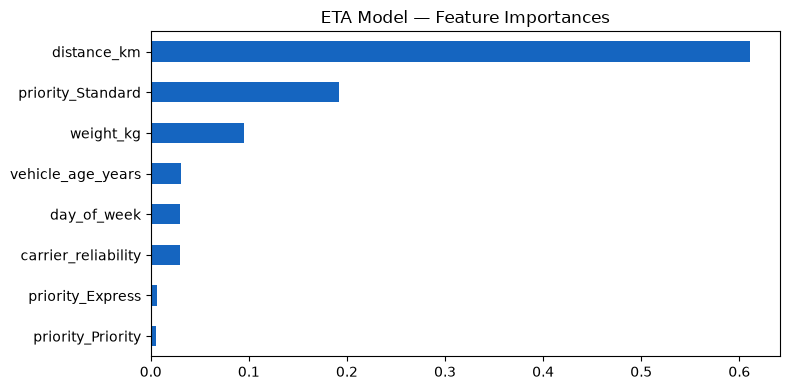

priority_Priority      0.005040
priority_Express       0.006332
carrier_reliability    0.029457
day_of_week            0.030021
vehicle_age_years      0.031120
weight_kg              0.095110
priority_Standard      0.191999
distance_km            0.610921
dtype: float64


In [7]:
# feature importances (great for the demo)

import matplotlib.pyplot as plt
rf   = pipeline.named_steps["rf"]
ohe  = pipeline.named_steps["prep"].named_transformers_["cat"]
cat_names = ohe.get_feature_names_out(FEATURES_CAT).tolist()
all_names = FEATURES_NUM + cat_names
importances = pd.Series(rf.feature_importances_, index=all_names).sort_values()

importances.plot(kind="barh", figsize=(8,4), color="#1565C0")
plt.title("ETA Model — Feature Importances")
plt.tight_layout(); plt.show()
print(importances)

In [8]:
# save model

os.makedirs("../models", exist_ok=True)
joblib.dump(pipeline, "../models/eta_rf.pkl")
print("✅ Saved ../models/eta_rf.pkl")

✅ Saved ../models/eta_rf.pkl
